### ELO328 - Procesamiento Digital de Imágenes
# Clase 14: An Introduction to Diffusion Models and Stable Diffusion
Prof. Nicolás Torres<br/>
<a href="mailto:nicolas.torresr@usm.cl">nicolas.torresr@usm.cl</a><br/>
Ingeniería Civil Telemática<br/>
Departamento de Electrónica<br/>
Universidad Técnica Federico Santa María

# Introducción

En 2022, la obra de Jason M. Allen ganó del concurso de arte de la Feria Estatal de Colorado.
<center>
<div align="center">
    <img src="img/theatre_d_opera_spatial.png" alt="" width="50%" align="center" />
</div>
“Théâtre D’opéra Spatial” (2022)
    </center>

# Diffusion Models

Los modelos de difusión son modelos generativos que aprenden de los datos durante el entrenamiento y generan ejemplos similares basados en lo que han aprendido. Básicamente, los modelos de difusión “destruyen” los datos agregando iterativamente ruido gaussiano y luego aprenden cómo recuperar los datos eliminando el ruido.

<div align="center">
    <img src="img/process.png" alt="" width="100%" align="center" />
</div>

# Vista de alto nivel del modelo de difusión

En pocas palabras, los modelos de difusión funcionan corrompiendo los datos de entrenamiento mediante la adición de ruido gaussiano (difusión hacia adelante) y luego aprendiendo a recuperar la información original invirtiendo este proceso de ruido paso a paso (difusión inversa). Una vez entrenados, estos modelos pueden generar nuevos datos mediante el muestreo de ruido gaussiano aleatorio y pasándolos por el proceso de eliminación de ruido aprendido.

<div align="center">
    <img src="img/stable-diffusion-illustration.png" alt="" width="90%" align="center" />
</div>

# Entrenamiento de alto nivel

Durante el entrenamiento, se utiliza un autoencoder para aprender una representación latente sin ruido usando el codificador. El decodificador reconstruye la versión original de la imagen a partir de la representación eficiente con la menor pérdida posible. El truco aquí es que desacoplaron la codificación del entrenamiento del modelo de difusión.

<div align="center">
    <img src="img/autoencoder-illustration.png" alt="" width="100%" align="center" />
</div>

# Stable Diffusion

<div align="center">
    <img src="img/text-to-image-illustration.png" alt="" width="80%" align="center" />
</div>

- Un LLM transforma el prompt en un embedding para alimentar al modelo de difusión.
- El modelo de difusión toma como entrada ruido gaussiano y lo elimina para acercarse al embedding.
- El decodificador toma la salida del modelo de difusión y la amplía a una imagen completa.

# U-Net architecture

En términos generales, los modelos de difusión utilizan algún tipo de variante de U-Net para aproximarse al proceso de difusión inversa.

<div align="center">
    <img src="img/U_Net.png" alt="" width="70%" align="center" />
</div>

# Classifier-Free Guidance 

Hasta entonces, la generación de imágenes de una clase específica era posible principalmente mediante la adición de la etiqueta de clase en la entrada, lo que se conoce comúnmente como Classifier Guidance. Sin embargo, Stable Diffusion es capaz de generar imágenes basadas en prompts detallados mediante la introducción de mecanismos de condicionamiento en el modelo de difusión interna, llamados Classifier-Free Guidance (CFG).

<div align="center">
    <img src="img/CFG.png" alt="" width="55%" align="center" />
</div>

# Condicionamiento

Para lograr el condicionamiento, la U-Net de eliminación de ruido del modelo de difusión interna usa un mecanismo de atención cruzada: Las entradas de texto se transforman primero en embeddings a través de un LLM. En el condicionamiento, mapeamos estas incrustaciones en la U-Net utilizando una capa de atención de múltiples cabezas, representada como Q, K y V en el diagrama.

<div align="center">
    <img src="img/conditioning_sd.png" alt="" width="70%" align="center" />
</div>

# Entrenamiento del modelo de difusión

Para el entrenamiento se utiliza una imagen con una descripción existente. Se añade ruido a la imagen codificada en intervalos de tiempo sucesivos. La descripción texto se incorpora mediante el modelo de lenguaje. El modelo de difusión recibe una versión con ruido de la imagen y el embedding de texto y necesita predecir el intervalo de tiempo anterior de la imagen. Se utiliza el descenso de gradiente en la diferencia de píxeles entre la imagen esperada y la predicción del modelo de difusión.

<div align="center">
    <img src="img/stable-diffusion-training.png" alt="" width="100%" align="center" />
</div>

# Arquitectura de Stable Diffusion durante el entrenamiento

Por un lado, durante el entrenamiento, las imágenes ($x_0$) se codifican a través del Encoder E, llegando a la representación latente de la imagen ($z_0$). En el proceso de difusión hacia adelante, la imagen sufre la adición de ruido gaussiano, obteniendo una imagen ruidosa ($z_T$). A continuación, la imagen pasa por la U-Net, con el fin de predecir el ruido presente en $z_T$. 

<div align="center">
    <img src="img/architecture_sd.png" alt="" width="60%" align="center" />
</div>

# Arquitectura de Stable Diffusion durante el muestreo

Durante el muestreo, no se realiza la difusión hacia adelante. En su lugar, se genera ruido gaussiano con las mismas dimensiones del espacio latente ($z_T$), que pasa por la U-Net en $T$ pasos. En cada paso $t$, la U-Net predice el ruido presente, eliminando solo una fracción para obtener la imagen en el siguiente paso $t-1$. Al finalizar los $T$ pasos, obtenemos la representación latente de la imagen generada ($z'_0$), que luego es transformada al espacio de píxeles ($X'_0$) mediante el decodificador $D$.

<div align="center">
    <img src="img/sampling_sd.png" alt="" width="55%" align="center" />
</div>

In [2]:
import tensorflow as tf
import keras
import numpy as np
import keras_cv
import sys

print("Python version:",sys.version)
print("Numpy version:",np.__version__)
print("Keras version:",keras.__version__)
print("TensorFlow version:",tf.__version__)
print("Keras-CV version:",keras_cv.__version__)

Python version: 3.10.12 (main, Jul  5 2023, 15:34:07) [Clang 14.0.6 ]
Numpy version: 1.26.3
Keras version: 3.0.0
TensorFlow version: 2.15.0
Keras-CV version: 0.8.1


In [3]:
import matplotlib.pyplot as plt
from keras_cv.models import StableDiffusion, StableDiffusionV2
from PIL import Image

In [4]:
def plot_images(images):
    total_images = len(images)
    if total_images < 2:
        plt.figure(figsize=(4, 4))
        plt.imshow(images[0])
        plt.axis('off')
    else:
        fig, axes = plt.subplots(1, 
                                 total_images, 
                                 figsize=(4*total_images, 4))
        for i in range(total_images):
            axes[i].imshow(images[i])
            axes[i].axis('off')
        plt.tight_layout()
    plt.show()

In [5]:
def generate(model, prompt, n = 3, steps = 25, seed = 123):
    images = model.text_to_image(
        prompt=prompt,
        batch_size=n,  # How many images to generate at once
        num_steps=steps,  # Number of iterations (controls image quality)
        seed=seed,  # Set this to always get the same image from the same prompt
    )
    plot_images(images)

In [6]:
sd2 = StableDiffusionV2(img_height=512, img_width=512, jit_compile=True)

By using this model checkpoint, you acknowledge that its usage is subject to the terms of the CreativeML Open RAIL++-M license at https://github.com/Stability-AI/stablediffusion/blob/main/LICENSE-MODEL


25/25 ━━━━━━━━━━━━━━━━━━━━ 1643s 65s/step


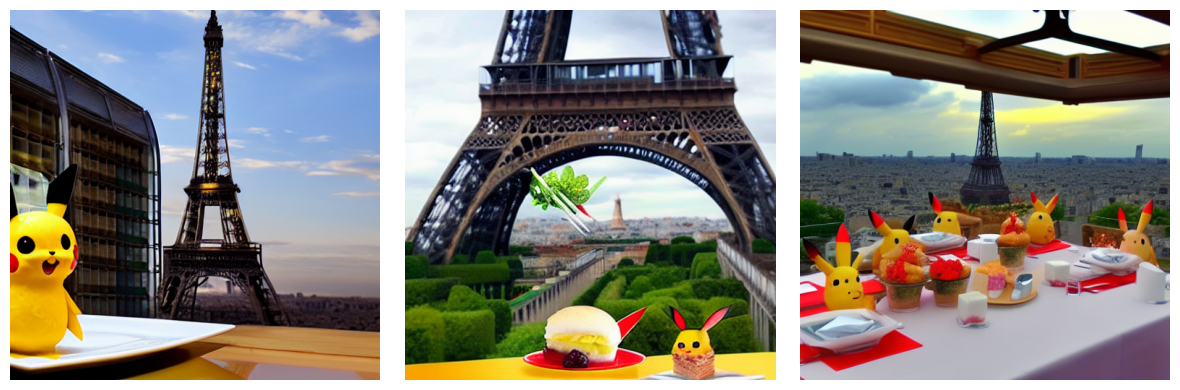

In [12]:
generate(sd2, "A pikachu fine dining with a view to the Eiffel Tower", n = 3, steps = 25)

25/25 ━━━━━━━━━━━━━━━━━━━━ 1729s 69s/step


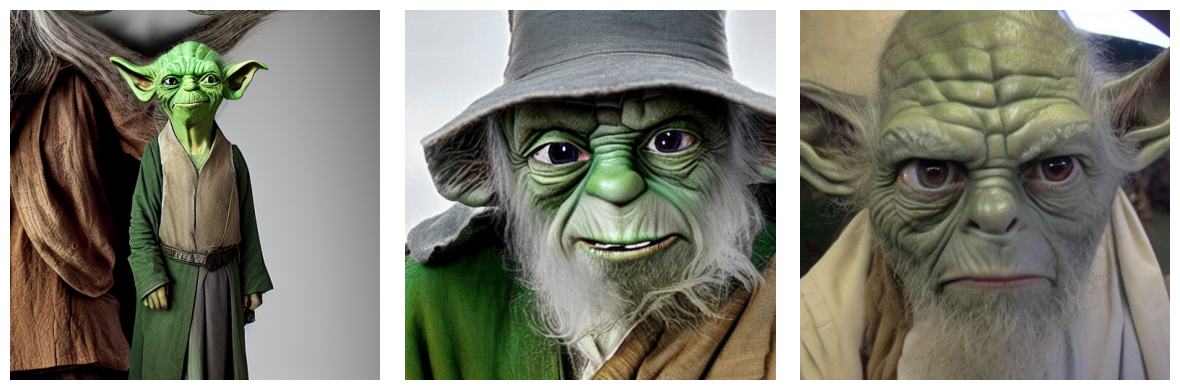

In [11]:
generate(sd2, "A person half Yoda half Gandalf", n = 3, steps = 25)